<a href="https://colab.research.google.com/github/192524103simats-star/CSA4705/blob/main/UNIT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=200, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier()
model.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model.predict(X_test)))

Training Accuracy: 1.0
Testing Accuracy: 0.9


In [ ]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = np.array([1, 2, 3, 4, 5, 6]).reshape(-1, 1)
y = np.array([2, 5, 10, 17, 26, 37])

for d in [1, 2, 5]:
    poly = PolynomialFeatures(degree=d)
    Xp = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(Xp, y)

    pred = model.predict(Xp)
    print("Degree:", d, "Error:", mean_squared_error(y, pred))

Degree: 1 Error: 6.222222222222221
Degree: 2 Error: 5.801414573812858e-29
Degree: 5 Error: 7.222021587298363e-28


In [ ]:
import numpy as np
from sklearn.linear_model import Lasso, Ridge

X = np.array([[1, 2], [2, 3], [3, 4], [4, 5]])
y = np.array([5, 8, 11, 14])

for model in [Lasso(alpha=0.1), Ridge(alpha=0.1)]:
    model.fit(X, y)
    print(type(model).__name__)
    print("Coefficients:", model.coef_)
    print("Predictions:", model.predict(X))

Lasso
Coefficients: [2.92000000e+00 1.33226763e-16]
Predictions: [ 5.12  8.04 10.96 13.88]
Ridge
Coefficients: [1.48514851 1.48514851]
Predictions: [ 5.04455446  8.01485149 10.98514851 13.95544554]


In [ ]:
for lr in [0.001, 0.01, 0.1]:
    w = 10

    for i in range(50):
        w = w - lr * 2 * w

    print("Learning Rate:", lr)
    print("Final Loss:", round(w**2, 5))

Learning Rate: 0.001
Final Loss: 81.85668
Learning Rate: 0.01
Final Loss: 13.26196
Learning Rate: 0.1
Final Loss: 0.0


In [ ]:
import numpy as np

a = np.float32(0.1)
b = np.float64(0.1)

print("Float32:", a)
print("Float64:", b)
print("Float32 Error:", abs(a - 0.1))
print("Float64 Error:", abs(b - 0.1))

Float32: 0.1
Float64: 0.1
Float32 Error: 0.0
Float64 Error: 0.0


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.svm import SVC

X, y = load_iris(return_X_y=True)

params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}

grid = GridSearchCV(SVC(), params, cv=3)
grid.fit(X, y)

random = RandomizedSearchCV(SVC(), params, n_iter=4, cv=3, random_state=42)
random.fit(X, y)

print("Grid Search:", grid.best_params_)
print("Random Search:", random.best_params_)
print("Grid Score:", grid.best_score_)
print("Random Score:", random.best_score_)

Grid Search: {'C': 1, 'kernel': 'linear'}
Random Search: {'kernel': 'linear', 'C': 1}
Grid Score: 0.9933333333333333
Random Score: 0.9933333333333333


In [1]:
import numpy as np

Q = np.zeros((3, 2))
alpha = 0.1
gamma = 0.9

for episode in range(100):
    state = np.random.randint(3)
    action = np.argmax(Q[state])

    reward = 10 if action == state % 2 else -5
    next_state = np.random.randint(3)

    Q[state, action] += alpha * (
        reward + gamma * np.max(Q[next_state]) - Q[state, action]
    )

print("Q Table:\n", Q)
print("Best Actions:", np.argmax(Q, axis=1))

Q Table:
 [[28.62422848  0.        ]
 [-0.5        30.56074624]
 [25.69868765  0.        ]]
Best Actions: [0 1 0]


In [2]:
import numpy as np
from sklearn.linear_model import Perceptron

X = np.array([[20, 30], [30, 40], [60, 70], [80, 90]])
y = np.array([0, 0, 1, 1])

model = Perceptron()
model.fit(X, y)

print("Predictions:", model.predict(X))

Predictions: [0 0 0 0]


In [3]:
import numpy as np
from sklearn.neural_network import MLPClassifier

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 1, 1, 0])

model = MLPClassifier(hidden_layer_sizes=(4,),
                      activation='tanh',
                      solver='lbfgs',
                      max_iter=5000,
                      random_state=42)

model.fit(X, y)

print("Predictions:", model.predict(X))

Predictions: [0 1 1 0]


In [4]:
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = MLPClassifier(hidden_layer_sizes=(10,),
                      max_iter=2000, random_state=42)

model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))

Accuracy: 0.9666666666666667


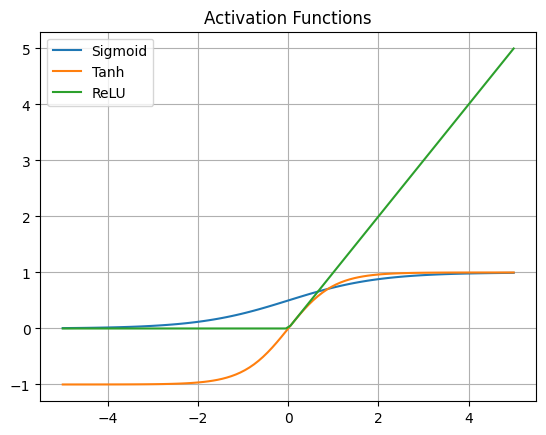

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 100)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")

plt.legend()
plt.grid()
plt.title("Activation Functions")
plt.show()

In [11]:
from sklearn.datasets import make_classification
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline

X, y = make_classification(n_samples=200, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

for act in ['relu', 'logistic', 'tanh']:
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(10,),
                      activation=act,
                      max_iter=3000,
                      random_state=42,
                      early_stopping=True)
    )

    model.fit(X_train, y_train)

    print(act, "Accuracy:",
          accuracy_score(y_test, model.predict(X_test)))

relu Accuracy: 0.45
logistic Accuracy: 0.5
tanh Accuracy: 0.325


In [7]:
import numpy as np

X = np.array([[1, 2]])
W1 = np.array([[0.5, 0.2], [0.3, 0.4]])
W2 = np.array([[0.6], [0.7]])

sigmoid = lambda x: 1 / (1 + np.exp(-x))

H = sigmoid(X @ W1)
O = sigmoid(H @ W2)

print("Hidden Output:", H)
print("Final Output:", O)

Hidden Output: [[0.75026011 0.73105858]]
Final Output: [[0.72350147]]


In [8]:
import numpy as np

x = np.array([[1, 0]])
y = np.array([[1]])

W1 = np.random.rand(2, 2)
W2 = np.random.rand(2, 1)
lr = 0.1

sig = lambda z: 1 / (1 + np.exp(-z))

h = sig(x @ W1)
o = sig(h @ W2)

error = o - y
dW2 = h.T @ error
dW1 = x.T @ (error @ W2.T * h * (1-h))

W1 -= lr * dW1
W2 -= lr * dW2

print("Output:", o)
print("Updated W1:\n", W1)
print("Updated W2:\n", W2)

Output: [[0.63509778]]
Updated W1:
 [[0.65304033 0.3102411 ]
 [0.35459864 0.58805596]]
Updated W2:
 [[0.73672232]
 [0.17071625]]


In [9]:
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

X = np.array([[1000], [1500], [2000], [2500], [3000]])
y = np.array([20, 30, 40, 50, 60])

model = MLPRegressor(hidden_layer_sizes=(10,),
                     max_iter=5000, random_state=42)

model.fit(X, y)

pred = model.predict(X)

print("Actual:", y)
print("Predicted:", pred.round(2))
print("MSE:", mean_squared_error(y, pred))

Actual: [20 30 40 50 60]
Predicted: [20.26 30.14 40.02 49.9  59.78]
MSE: 0.02883719539460384


In [10]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, accuracy_score

X = np.array([[10], [20], [30], [80], [90], [100]])
y = np.array([0, 0, 0, 1, 1, 1])

model = LogisticRegression()
model.fit(X, y)

pred = model.predict(X)
prob = model.predict_proba(X)[:, 1]

print("Predictions:", pred)
print("Accuracy:", accuracy_score(y, pred))
print("Binary Cross Entropy:", log_loss(y, prob))

Predictions: [0 0 0 1 1 1]
Accuracy: 1.0
Binary Cross Entropy: 0.0014207203099515138
